In [36]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)
df = pd.read_csv("./fmnist_small.csv")

X = df.loc[:, 'pixel1':].to_numpy()
y = df.loc[:, 'label'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# (batch, height, width, channels) is the layout Conv2D expects
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

y_train = encoder.fit_transform(y_train.reshape(-1, 1))
y_test = encoder.transform(y_test.reshape(-1, 1))

In [37]:
class Layer:
    def __init__(self, n_inputs, n_neurons):
        self.weights = np.random.randn(n_inputs, n_neurons) * np.sqrt(2.0 / n_inputs)
        self.biases = np.zeros((1, n_neurons))

    def forward(self, x):
        self.inputs = x
        self.output = np.dot(x, self.weights) + self.biases

    def backward(self, dvalues):
        self.dweights = np.dot(self.inputs.T, dvalues)
        self.dbiases = np.sum(dvalues, axis=0, keepdims=True)
        self.dinputs = np.dot(dvalues, self.weights.T)


class Activation_ReLU:
    def forward(self, inputs):
        self.inputs = inputs
        self.output = np.maximum(0, inputs)

    def backward(self, dvalues):
        self.dinputs = dvalues.copy()
        self.dinputs[self.inputs <= 0] = 0


class Activation_Softmax:
    def forward(self, inputs):
        self.inputs = inputs
        exp_values = np.exp(inputs - np.max(inputs, axis=1, keepdims=True))
        self.output = exp_values / np.sum(exp_values, axis=1, keepdims=True)


class LossAndSoftmax:
    def __init__(self):
        self.softmax = Activation_Softmax()

    def forward(self, logits, y):
        self.softmax.forward(logits)
        self.output = self.softmax.output
        clipped = np.clip(self.output, 1e-7, 1 - 1e-7)
        if y.ndim == 2:
            confidences = np.sum(clipped * y, axis=1)
        else:
            confidences = clipped[range(len(clipped)), y]
        return np.mean(-np.log(confidences))

    def backward(self, dvalues, y):
        if y.ndim == 2:
            y = np.argmax(y, axis=1)
        samples = len(dvalues)
        self.dinputs = dvalues.copy()
        self.dinputs[range(samples), y] -= 1
        self.dinputs /= samples

In [38]:
class Conv2D:
    def __init__(self, filters, kernel_size=3, stride=1, padding=0, in_channels=1):
        self.filters = filters
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding
        fan_in = kernel_size * kernel_size * in_channels
        self.weights = np.random.randn(kernel_size, kernel_size, in_channels, filters) * np.sqrt(2.0 / fan_in)
        self.biases = np.zeros(filters)

    def im2col(self, inputs):
        batch_size, in_h, in_w, in_c = inputs.shape
        if self.padding > 0:
            p = self.padding
            inputs = np.pad(inputs, ((0, 0), (p, p), (p, p), (0, 0)), mode='constant')
            in_h += 2 * p
            in_w += 2 * p
        out_h = (in_h - self.kernel_size) // self.stride + 1
        out_w = (in_w - self.kernel_size) // self.stride + 1
        col = np.zeros((batch_size * out_h * out_w, self.kernel_size * self.kernel_size * in_c))
        for y in range(self.kernel_size):
            y_max = y + self.stride * out_h
            for x in range(self.kernel_size):
                x_max = x + self.stride * out_w
                for c in range(in_c):
                    col[:, (y * self.kernel_size + x) * in_c + c] = \
                        inputs[:, y:y_max:self.stride, x:x_max:self.stride, c].ravel()
        return col, out_h, out_w

    def forward(self, inputs):
        self.inputs = inputs
        batch_size = inputs.shape[0]
        col, out_h, out_w = self.im2col(inputs)
        W_col = self.weights.reshape(-1, self.filters)
        out = np.dot(col, W_col) + self.biases
        self.output = out.reshape(batch_size, out_h, out_w, self.filters)
        return self.output

    def col2im(self, col, input_shape):
        batch_size, in_h, in_w, in_c = input_shape
        in_h += 2 * self.padding
        in_w += 2 * self.padding
        out_h = (in_h - self.kernel_size) // self.stride + 1
        out_w = (in_w - self.kernel_size) // self.stride + 1
        img = np.zeros((batch_size, in_h, in_w, in_c))
        for y in range(self.kernel_size):
            y_max = y + self.stride * out_h
            for x in range(self.kernel_size):
                x_max = x + self.stride * out_w
                for c in range(in_c):
                    img[:, y:y_max:self.stride, x:x_max:self.stride, c] += \
                        col[:, (y * self.kernel_size + x) * in_c + c].reshape(batch_size, out_h, out_w)
        return img

    def backward(self, dvalues):
        dvalues_flat = dvalues.reshape(-1, self.filters)
        col, _, _ = self.im2col(self.inputs)
        self.dweights = np.dot(col.T, dvalues_flat).reshape(self.weights.shape)
        self.dbiases = np.sum(dvalues_flat, axis=0)

        W_col = self.weights.reshape(-1, self.filters)
        dcol = np.dot(dvalues_flat, W_col.T)
        dinputs_padded = self.col2im(dcol, self.inputs.shape)

        p = self.padding
        self.dinputs = dinputs_padded[:, p:-p, p:-p, :] if p > 0 else dinputs_padded
        return self.dinputs


class MaxPool2D:
    def __init__(self, pool_size=2, stride=2):
        self.pool_size = pool_size
        self.stride = stride

    def forward(self, inputs):
        self.inputs = inputs
        batch_size, in_h, in_w, in_c = inputs.shape
        out_h = (in_h - self.pool_size) // self.stride + 1
        out_w = (in_w - self.pool_size) // self.stride + 1

        reshaped = inputs[:, :out_h * self.stride, :out_w * self.stride, :].copy()
        reshaped = reshaped.reshape(batch_size, out_h, self.stride, out_w, self.stride, in_c)
        reshaped = reshaped.transpose(0, 1, 3, 5, 2, 4)
        reshaped = reshaped.reshape(batch_size, out_h, out_w, in_c, -1)

        self.output = np.max(reshaped, axis=-1)
        max_indices = np.argmax(reshaped, axis=-1)

        self.mask = np.zeros_like(reshaped, dtype=bool)
        batch_idx, h_idx, w_idx, c_idx = np.indices(max_indices.shape)
        self.mask[batch_idx, h_idx, w_idx, c_idx, max_indices] = True
        return self.output

    def backward(self, dvalues):
        batch_size, out_h, out_w, in_c = dvalues.shape
        expanded_grad = np.zeros(self.mask.shape, dtype=np.float32)
        expanded_grad[self.mask] = dvalues.ravel()

        expanded_grad = expanded_grad.reshape(batch_size, out_h, out_w, in_c, self.stride, self.stride)
        expanded_grad = expanded_grad.transpose(0, 1, 4, 2, 5, 3)
        self.dinputs = expanded_grad.reshape(batch_size, out_h * self.stride, out_w * self.stride, in_c)

        if self.dinputs.shape != self.inputs.shape:
            pad_h = self.inputs.shape[1] - self.dinputs.shape[1]
            pad_w = self.inputs.shape[2] - self.dinputs.shape[2]
            self.dinputs = np.pad(self.dinputs, ((0, 0), (0, pad_h), (0, pad_w), (0, 0)))
        return self.dinputs

In [39]:
class Optimizer_SGD:
    def __init__(self, learning_rate=1.0, decay=0., momentum=0.):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.momentum = momentum
        self.iterations = 0

    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate / (1. + self.decay * self.iterations)

    def update_params(self, layer):
        if self.momentum:
            if not hasattr(layer, 'weight_momentums'):
                layer.weight_momentums = np.zeros_like(layer.weights)
                layer.bias_momentums = np.zeros_like(layer.biases)
            weight_updates = self.momentum * layer.weight_momentums - self.current_learning_rate * layer.dweights
            layer.weight_momentums = weight_updates
            bias_updates = self.momentum * layer.bias_momentums - self.current_learning_rate * layer.dbiases
            layer.bias_momentums = bias_updates
        else:
            weight_updates = -self.current_learning_rate * layer.dweights
            bias_updates = -self.current_learning_rate * layer.dbiases

        layer.weights += weight_updates
        layer.biases += bias_updates

    def post_update_params(self):
        self.iterations += 1

In [40]:
conv1 = Conv2D(filters=32, kernel_size=3, padding=1, in_channels=1)
activation1 = Activation_ReLU()
pool1 = MaxPool2D(pool_size=2, stride=2)
layer1 = Layer(14 * 14 * 32, 128)
activation2 = Activation_ReLU()
layer2 = Layer(128, 10)
softmax2 = Activation_Softmax()
loss_func = LossAndSoftmax()
optimizer = Optimizer_SGD(learning_rate=0.01, decay=1e-3, momentum=0.9)

In [41]:
def forward_pass(X_batch, y_true):
    conv1.forward(X_batch)
    activation1.forward(conv1.output)
    pool1.forward(activation1.output)

    flatten_output = pool1.output.reshape(X_batch.shape[0], -1)
    layer1.forward(flatten_output)
    activation2.forward(layer1.output)
    layer2.forward(activation2.output)
    loss = loss_func.forward(layer2.output, y_true)
    return loss

In [42]:
def backward_pass(dvalues, y_batch):
    loss_func.backward(dvalues, y_batch)
    layer2.backward(loss_func.dinputs)
    activation2.backward(layer2.dinputs)
    layer1.backward(activation2.dinputs)

    pool_grad = layer1.dinputs.reshape(pool1.output.shape)
    pool1.backward(pool_grad)
    activation1.backward(pool1.dinputs)
    conv1.backward(activation1.dinputs)

In [43]:
batch_size = 64
num_epochs = 5

for epoch in range(1, num_epochs + 1):
    permutation = np.random.permutation(X_train.shape[0])
    X_train_shuffled = X_train[permutation]
    y_train_shuffled = y_train[permutation]

    epoch_loss = 0.0
    epoch_accuracy = 0.0
    num_batches = X_train.shape[0] // batch_size

    for batch_idx in range(num_batches):
        start = batch_idx * batch_size
        end = start + batch_size
        X_batch = X_train_shuffled[start:end]
        y_batch = y_train_shuffled[start:end]

        loss = forward_pass(X_batch, y_batch)

        predictions = np.argmax(layer2.output, axis=1)
        true_labels = np.argmax(y_batch, axis=1)
        batch_accuracy = np.mean(predictions == true_labels)

        backward_pass(loss_func.output, y_batch)

        optimizer.pre_update_params()
        optimizer.update_params(layer2)
        optimizer.update_params(layer1)
        optimizer.update_params(conv1)
        optimizer.post_update_params()

        epoch_loss += loss
        epoch_accuracy += batch_accuracy

    avg_loss = epoch_loss / num_batches
    avg_accuracy = epoch_accuracy / num_batches
    print(f"Epoch {epoch}: Loss = {avg_loss:.4f}, Accuracy = {avg_accuracy:.4f}")

Epoch 1: Loss = 0.9581, Accuracy = 0.6554
Epoch 2: Loss = 0.5802, Accuracy = 0.7806
Epoch 3: Loss = 0.5092, Accuracy = 0.8079
Epoch 4: Loss = 0.4481, Accuracy = 0.8300
Epoch 5: Loss = 0.3958, Accuracy = 0.8577


(1200, 28, 28, 1)
5


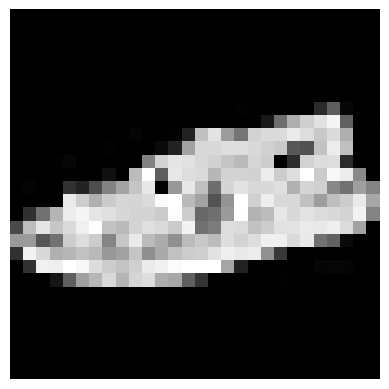

Test Accuracy: 0.8467


In [44]:
print(X_test.shape)
loss = forward_pass(X_test, y_test)

test_predictions = np.argmax(loss_func.output, axis=1)
test_true = np.argmax(y_test, axis=1)
test_accuracy = np.mean(test_predictions == test_true)

print(test_predictions[17])
plt.imshow(X_test[17, :, :, 0], cmap="gray")
plt.axis('off')
plt.show()
print(f"Test Accuracy: {test_accuracy:.4f}")

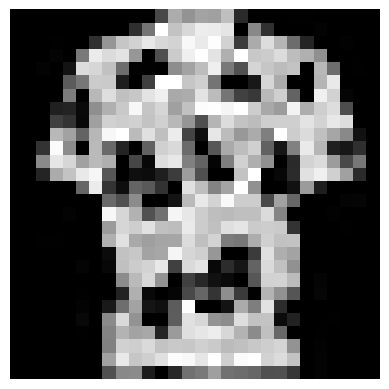

Predicted: 0, True: 6


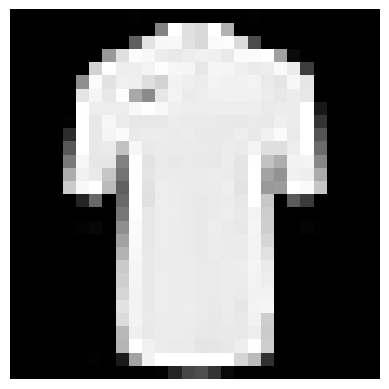

Predicted: 6, True: 0


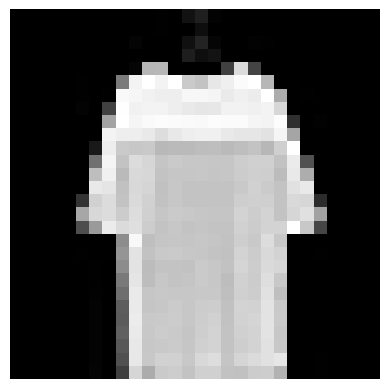

Predicted: 4, True: 3


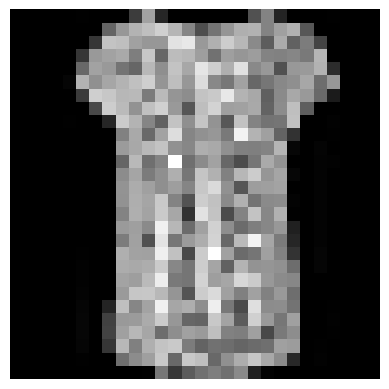

Predicted: 0, True: 6


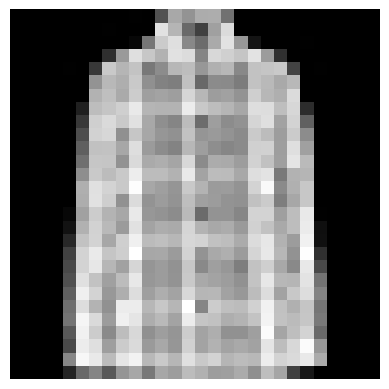

Predicted: 4, True: 6


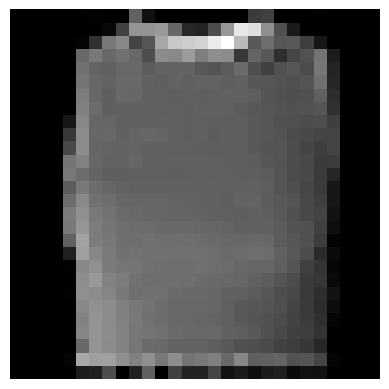

Predicted: 2, True: 0


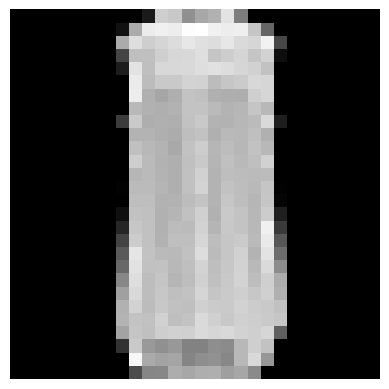

Predicted: 3, True: 6


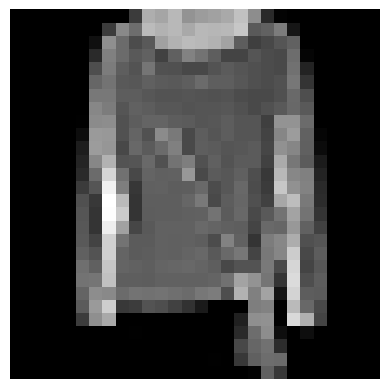

Predicted: 2, True: 6


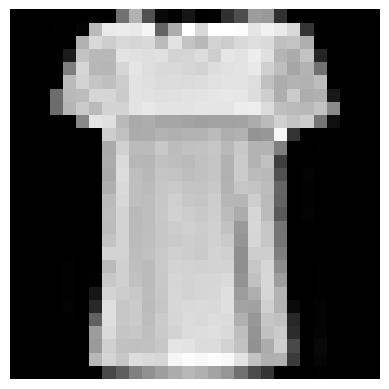

Predicted: 0, True: 6


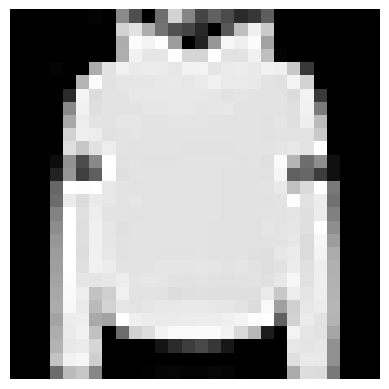

Predicted: 4, True: 2


In [45]:
incorrect_guesses = np.where(test_predictions != test_true)[0]
first_10_incorrect = incorrect_guesses[:10]

for idx in first_10_incorrect:
    plt.imshow(X_test[idx, :, :, 0], cmap="gray")
    plt.axis('off')
    plt.show()
    print(f"Predicted: {test_predictions[idx]}, True: {test_true[idx]}")

Predicted: Sandal


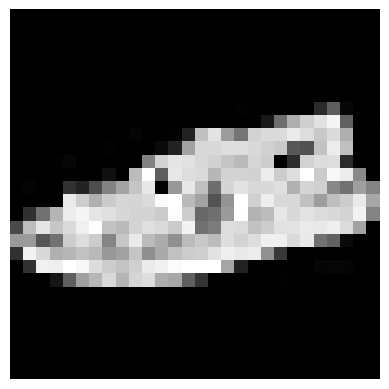

In [46]:
img_array = X_test[17, :, :, 0]
img_flattened = img_array.reshape(1, 28, 28, 1)

conv1.forward(img_flattened)
activation1.forward(conv1.output)
pool1.forward(activation1.output)

flatten_output = pool1.output.reshape(1, -1)
layer1.forward(flatten_output)
activation2.forward(layer1.output)
layer2.forward(activation2.output)
softmax2.forward(layer2.output)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

predicted_class = np.argmax(softmax2.output, axis=1)[0]
print("Predicted:", class_names[predicted_class])

plt.imshow(img_array, cmap="gray")
plt.axis('off')
plt.show()

In [47]:
class ModelSaver:
    @staticmethod
    def save_model(conv1, layer1, layer2, path='model.npz'):
        np.savez(path,
                 conv1_weights=conv1.weights, conv1_biases=conv1.biases,
                 layer1_weights=layer1.weights, layer1_biases=layer1.biases,
                 layer2_weights=layer2.weights, layer2_biases=layer2.biases)
        print(f"Model saved to '{path}'")

    @staticmethod
    def load_model(conv1, layer1, layer2, path='model.npz'):
        data = np.load(path)
        conv1.weights = data['conv1_weights']
        conv1.biases = data['conv1_biases']
        layer1.weights = data['layer1_weights']
        layer1.biases = data['layer1_biases']
        layer2.weights = data['layer2_weights']
        layer2.biases = data['layer2_biases']
        print(f"Model loaded from '{path}'")


ModelSaver.save_model(conv1, layer1, layer2)

Model saved to 'model.npz'
